In [11]:
# Сравнительный анализ методов предварительной обработки
# медицинских изображений (Chest X-Ray Pneumonia)

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. Настройка пути к данным
data_dir = r"chest_xray/train"

normal_dir = os.path.join(data_dir, "NORMAL")
pneumonia_dir = os.path.join(data_dir, "PNEUMONIA")

# 2. Загрузка примеров изображений
def load_sample(folder, index=0):
    files = sorted([f for f in os.listdir(folder) if f.endswith(('.jpeg', '.jpg', '.png'))])
    path = os.path.join(folder, files[index])
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return img, files[index]

img_normal, name_n = load_sample(normal_dir, 0)
img_pneumo, name_p = load_sample(pneumonia_dir, 0)

print(f"Normal: {name_n}, shape={img_normal.shape}, dtype={img_normal.dtype}, range=[{img_normal.min()}, {img_normal.max()}]")
print(f"Pneumonia: {name_p}, shape={img_pneumo.shape}, dtype={img_pneumo.dtype}, range=[{img_pneumo.min()}, {img_pneumo.max()}]")

Normal: IM-0115-0001.jpeg, shape=(1858, 2090), dtype=uint8, range=[0, 255]
Pneumonia: person1000_bacteria_2931.jpeg, shape=(760, 1152), dtype=uint8, range=[0, 255]


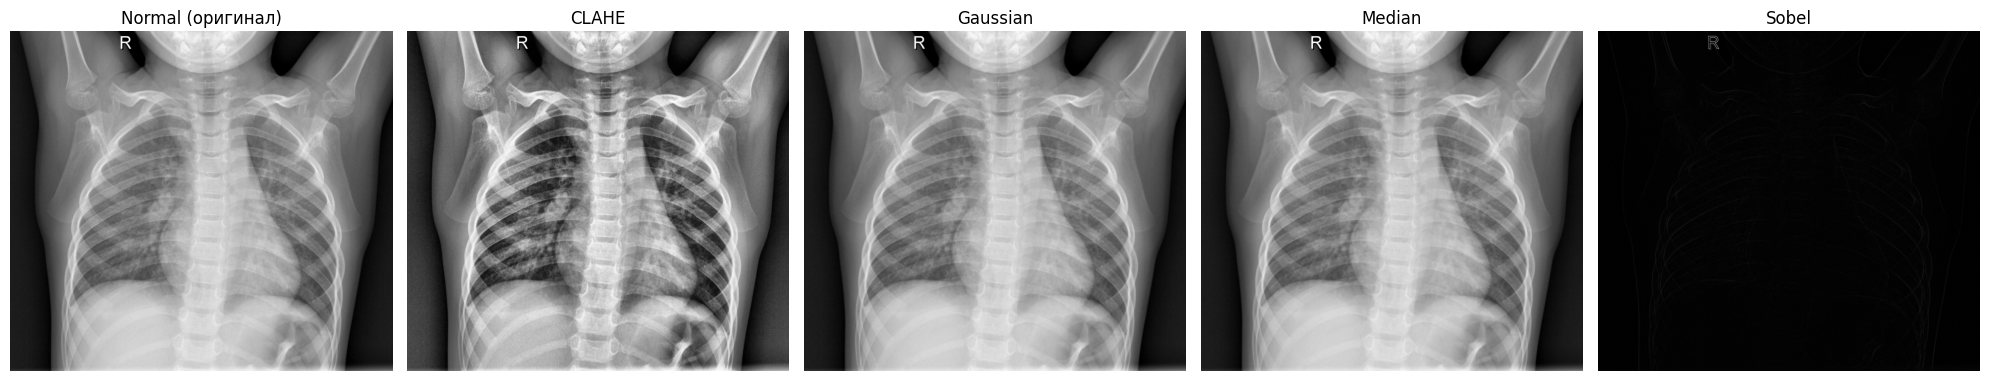

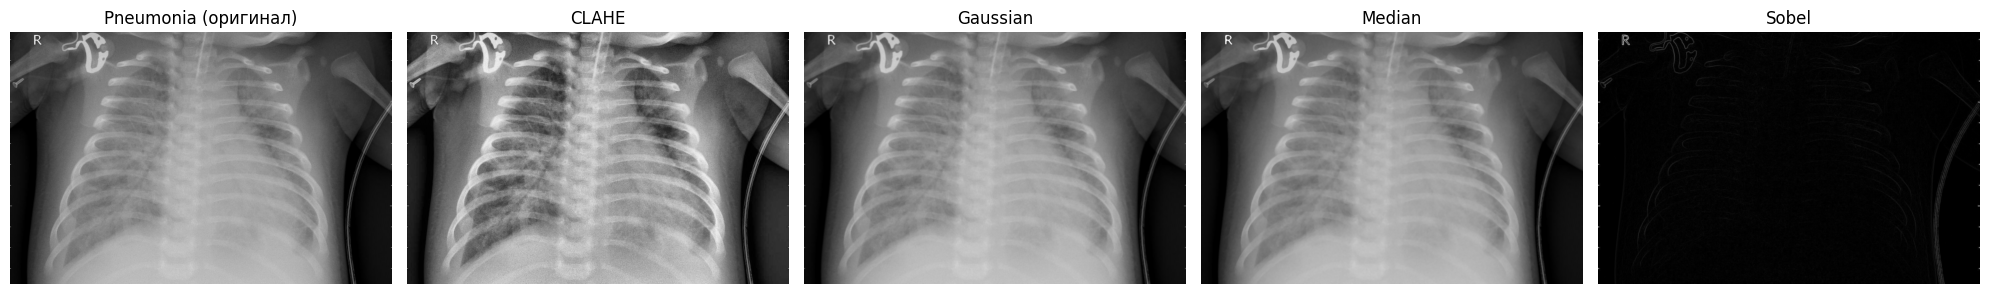

In [12]:
# 3. Определение методов предварительной обработки
def apply_clahe(img, clip_limit=2.0, tile_grid=(8, 8)):
    """CLAHE: ограниченное адаптивное выравнивание гистограммы"""
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    return clahe.apply(img)

def apply_gaussian(img, ksize=5, sigma=0):
    """Гауссово размытие для подавления шума"""
    return cv2.GaussianBlur(img, (ksize, ksize), sigma)

def apply_median(img, ksize=5):
    """Медианный фильтр"""
    return cv2.medianBlur(img, ksize)

def apply_sobel(img):
    """Выделение границ оператором Собеля"""
    grad_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(grad_x**2 + grad_y**2)
    return cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 4. Визуализация "до/после"
def show_comparison(original, processed_dict, title_orig="Оригинал"):
    n = len(processed_dict) + 1
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    
    axes[0].imshow(original, cmap='gray')
    axes[0].set_title(title_orig)
    axes[0].axis('off')
    
    for ax, (name, img) in zip(axes[1:], processed_dict.items()):
        ax.imshow(img, cmap='gray')
        ax.set_title(name)
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

# Для нормального снимка
processed_normal = {
    "CLAHE": apply_clahe(img_normal),
    "Gaussian": apply_gaussian(img_normal),
    "Median": apply_median(img_normal),
    "Sobel": apply_sobel(img_normal),
}
show_comparison(img_normal, processed_normal, "Normal (оригинал)")

# Для снимка с пневмонией
processed_pneumo = {
    "CLAHE": apply_clahe(img_pneumo),
    "Gaussian": apply_gaussian(img_pneumo),
    "Median": apply_median(img_pneumo),
    "Sobel": apply_sobel(img_pneumo),
}
show_comparison(img_pneumo, processed_pneumo, "Pneumonia (оригинал)")

In [13]:
# 5. Количественная оценка: PSNR и SSIM
def evaluate_metrics(original, processed, label=""):
    # SSIM требует, чтобы изображения были одного размера
    if original.shape != processed.shape:
        processed = cv2.resize(processed, (original.shape[1], original.shape[0]))
    
    p = psnr(original, processed, data_range=255)
    s = ssim(original, processed, data_range=255)
    print(f"{label:20s} | PSNR = {p:.2f} dB | SSIM = {s:.4f}")
    return p, s

print("=" * 60)
print("Оценка качества предварительной обработки (Normal)")
print("=" * 60)
evaluate_metrics(img_normal, apply_clahe(img_normal), "CLAHE")
evaluate_metrics(img_normal, apply_gaussian(img_normal), "Gaussian")
evaluate_metrics(img_normal, apply_median(img_normal), "Median")
evaluate_metrics(img_normal, apply_sobel(img_normal), "Sobel")

print("\n" + "=" * 60)
print("Оценка качества предварительной обработки (Pneumonia)")
print("=" * 60)
evaluate_metrics(img_pneumo, apply_clahe(img_pneumo), "CLAHE")
evaluate_metrics(img_pneumo, apply_gaussian(img_pneumo), "Gaussian")
evaluate_metrics(img_pneumo, apply_median(img_pneumo), "Median")
evaluate_metrics(img_pneumo, apply_sobel(img_pneumo), "Sobel")

Оценка качества предварительной обработки (Normal)
CLAHE                | PSNR = 19.94 dB | SSIM = 0.8548
Gaussian             | PSNR = 41.33 dB | SSIM = 0.9573
Median               | PSNR = 40.62 dB | SSIM = 0.9341
Sobel                | PSNR = 5.22 dB | SSIM = 0.0592

Оценка качества предварительной обработки (Pneumonia)
CLAHE                | PSNR = 21.09 dB | SSIM = 0.8313
Gaussian             | PSNR = 38.45 dB | SSIM = 0.9626
Median               | PSNR = 36.88 dB | SSIM = 0.9353
Sobel                | PSNR = 6.25 dB | SSIM = 0.0746


(np.float64(6.248747217777614), np.float64(0.07458987040605193))

In [14]:
# 6. Связь с диагностикой
# показываем, что предобработка влияет на "диагностическую ценность"
# простые признаки (гистограмма) + логистическая регрессия

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, recall_score, f1_score

def extract_hist_features(img, bins=32):
    """Извлекает нормированную гистограмму как признак"""
    hist = cv2.calcHist([img], [0], None, [bins], [0, 256]).flatten()
    hist = hist / hist.sum()
    return hist

def build_dataset(folder_normal, folder_pneumo, max_per_class=200, preprocess_fn=None):
    """Собирает датасет из изображений, применяя (опционально) предобработку"""
    X, y = [], []
    for label, folder in [(0, folder_normal), (1, folder_pneumo)]:
        files = sorted([f for f in os.listdir(folder) if f.endswith(('.jpeg', '.jpg', '.png'))])[:max_per_class]
        for f in files:
            path = os.path.join(folder, f)
            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            img = cv2.resize(img, (256, 256))
            if preprocess_fn is not None:
                img = preprocess_fn(img)
            X.append(extract_hist_features(img))
            y.append(label)
    return np.array(X), np.array(y)

# Собираем версии датасета без предобработки, с CLAHE, с Gaussian
print("Сбор данных (это может занять несколько секунд)...")
X_orig, y_orig = build_dataset(normal_dir, pneumonia_dir, max_per_class=150, preprocess_fn=None)
X_clahe, _ = build_dataset(normal_dir, pneumonia_dir, max_per_class=150, preprocess_fn=apply_clahe)
X_gauss, _ = build_dataset(normal_dir, pneumonia_dir, max_per_class=150, preprocess_fn=apply_gaussian)

# Разбиение и обучение
for name, X in [("Без обработки", X_orig), ("CLAHE", X_clahe), ("Gaussian", X_gauss)]:
    X_train, X_test, y_train, y_test = train_test_split(X, y_orig, test_size=0.3, random_state=42, stratify=y_orig)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    print(f"\n--- {name} ---")
    print(f"Recall (Pneumonia): {rec:.3f} | F1 (Pneumonia): {f1:.3f}")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Pneumonia"]))

Сбор данных (это может занять несколько секунд)...

--- Без обработки ---
Recall (Pneumonia): 0.667 | F1 (Pneumonia): 0.706
              precision    recall  f1-score   support

      Normal       0.70      0.78      0.74        45
   Pneumonia       0.75      0.67      0.71        45

    accuracy                           0.72        90
   macro avg       0.72      0.72      0.72        90
weighted avg       0.72      0.72      0.72        90


--- CLAHE ---
Recall (Pneumonia): 0.689 | F1 (Pneumonia): 0.705
              precision    recall  f1-score   support

      Normal       0.70      0.73      0.72        45
   Pneumonia       0.72      0.69      0.70        45

    accuracy                           0.71        90
   macro avg       0.71      0.71      0.71        90
weighted avg       0.71      0.71      0.71        90


--- Gaussian ---
Recall (Pneumonia): 0.600 | F1 (Pneumonia): 0.651
              precision    recall  f1-score   support

      Normal       0.65      0.76 